In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
file_path = "../data/cleaned_transactions.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 511566
Columns: 9


C:\Users\USER\AppData\Local\Temp\ipykernel_27804\2758030996.py:3: DtypeWarning: Columns (0: Invoice) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


In [3]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

customer_df = df.dropna(
    subset=["Customer ID"]
).copy()

print("Customer records:", len(customer_df))
print("Unique customers:", customer_df["Customer ID"].nunique())

Customer records: 407664
Unique customers: 4312


In [4]:
analysis_date = customer_df["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Analysis date:", analysis_date)

Analysis date: 2010-12-10 20:01:00


In [5]:
rfm = customer_df.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (analysis_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Sales", "sum")
).reset_index()

rfm.head()

,Customer ID,Recency,Frequency,Monetary
0,12346.0,165,11,372.86
1,12347.0,3,2,1323.32
2,12348.0,74,1,222.16
3,12349.0,43,3,2671.14
4,12351.0,11,1,300.93


In [6]:
print("RFM shape:", rfm.shape)

print("\nMissing values:")
print(rfm.isnull().sum())

print("\nRFM statistics:")
print(rfm[["Recency", "Frequency", "Monetary"]].describe())

RFM shape: (4312, 4)

Missing values:
Customer ID    0
Recency        0
Frequency      0
Monetary       0
dtype: int64

RFM statistics:
           Recency    Frequency       Monetary
count  4312.000000  4312.000000    4312.000000
mean     91.171846     4.456169    2048.238236
std      96.860633     8.170812    8914.481280
min       1.000000     1.000000       2.950000
25%      18.000000     1.000000     307.987500
50%      53.000000     2.000000     706.020000
75%     136.000000     5.000000    1723.142500
max     374.000000   205.000000  349164.350000


In [7]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,12346.0,165,11,372.86,2,5,2
1,12347.0,3,2,1323.32,5,2,4
2,12348.0,74,1,222.16,2,1,1
3,12349.0,43,3,2671.14,3,3,5
4,12351.0,11,1,300.93,5,1,2


In [9]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(int)
    + rfm["F_Score"].astype(int)
    + rfm["M_Score"].astype(int)
)

rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,165,11,372.86,2,5,2,9
1,12347.0,3,2,1323.32,5,2,4,11
2,12348.0,74,1,222.16,2,1,1,4
3,12349.0,43,3,2671.14,3,3,5,11
4,12351.0,11,1,300.93,5,1,2,8


In [10]:
rfm["RFM_Score"].value_counts().sort_index()

RFM_Score
3     201
4     342
5     373
6     325
7     397
8     382
9     347
10    347
11    379
12    298
13    288
14    283
15    350
Name: count, dtype: int64

In [11]:
rfm_features = rfm[
    ["Recency", "Frequency", "Monetary"]
]

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_features)

print("Scaled RFM shape:", rfm_scaled.shape)

Scaled RFM shape: (4312, 3)


In [12]:
inertia = []

K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(rfm_scaled)
    
    inertia.append(kmeans.inertia_)

print("Inertia values:")
for k, value in zip(K_range, inertia):
    print(f"K={k}: {value:.2f}")

Inertia values:
K=2: 8795.31
K=3: 5158.90
K=4: 3586.94
K=5: 2738.84
K=6: 2238.56
K=7: 1818.17
K=8: 1602.17
K=9: 1409.62
K=10: 1270.29


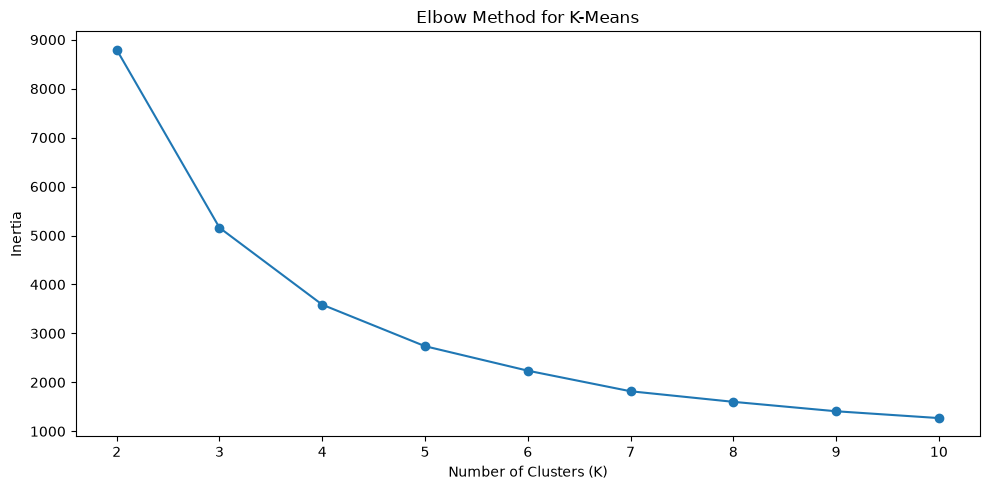

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(
    list(K_range),
    inertia,
    marker="o"
)

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.xticks(list(K_range))

plt.tight_layout()
plt.show()

In [14]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    cluster_labels = kmeans.fit_predict(rfm_scaled)
    
    score = silhouette_score(
        rfm_scaled,
        cluster_labels
    )
    
    silhouette_scores.append(score)

print("Silhouette Scores:")

for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K={k}: {score:.4f}")

Silhouette Scores:
K=2: 0.9038
K=3: 0.5890
K=4: 0.6113
K=5: 0.6139
K=6: 0.5197
K=7: 0.4945
K=8: 0.4946
K=9: 0.4306
K=10: 0.4085


In [15]:
candidate_results = {}

for k in [2, 4, 5]:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(rfm_scaled)
    
    temp = rfm.copy()
    temp["Cluster"] = labels
    
    candidate_results[k] = temp

print("Candidate clustering solutions created!")

Candidate clustering solutions created!


In [16]:
candidate_results[2].groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

,Recency,Frequency,Monetary
Cluster,,,
0,5.82,84.36,86989.63
1,91.61,4.05,1612.64


In [17]:
candidate_results[2]["Cluster"].value_counts().sort_index()

Cluster
0      22
1    4290
Name: count, dtype: int64

In [18]:
candidate_results[4].groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

,Recency,Frequency,Monetary
Cluster,,,
0,14.27,46.05,28018.43
1,43.07,4.43,1710.80
2,5.60,113.60,215543.67
3,242.98,1.66,596.88


In [19]:
candidate_results[4]["Cluster"].value_counts().sort_index()

Cluster
0      59
1    3201
2       5
3    1047
Name: count, dtype: int64

In [20]:
candidate_results[5].groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

,Recency,Frequency,Monetary
Cluster,,,
0,16.77,21.77,12247.52
1,44.70,3.77,1377.08
2,243.86,1.66,599.79
3,6.00,89.67,264709.20
4,3.70,118.10,66359.35


In [21]:
candidate_results[5]["Cluster"].value_counts().sort_index()

Cluster
0     208
1    3053
2    1038
3       3
4      10
Name: count, dtype: int64

In [22]:
candidate_results[2].groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

,Recency,Frequency,Monetary
Cluster,,,
0,5.82,84.36,86989.63
1,91.61,4.05,1612.64


In [23]:
candidate_results[2]["Cluster"].value_counts().sort_index()

Cluster
0      22
1    4290
Name: count, dtype: int64

In [24]:
candidate_results[4].groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

,Recency,Frequency,Monetary
Cluster,,,
0,14.27,46.05,28018.43
1,43.07,4.43,1710.80
2,5.60,113.60,215543.67
3,242.98,1.66,596.88


In [25]:
candidate_results[4]["Cluster"].value_counts().sort_index()

Cluster
0      59
1    3201
2       5
3    1047
Name: count, dtype: int64

In [26]:
final_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = final_kmeans.fit_predict(rfm_scaled)

rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Cluster
0,12346.0,165,11,372.86,2,5,2,9,3
1,12347.0,3,2,1323.32,5,2,4,11,1
2,12348.0,74,1,222.16,2,1,1,4,1
3,12349.0,43,3,2671.14,3,3,5,11,1
4,12351.0,11,1,300.93,5,1,2,8,1


In [27]:
cluster_summary = rfm.groupby("Cluster").agg(
    Customers=("Customer ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

cluster_summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,59,14.27,46.05,28018.43
1,3201,43.07,4.43,1710.80
2,5,5.60,113.60,215543.67
3,1047,242.98,1.66,596.88


In [28]:
cluster_summary = cluster_summary.sort_values(
    "Avg_Monetary",
    ascending=False
)

cluster_summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
2,5,5.60,113.60,215543.67
0,59,14.27,46.05,28018.43
1,3201,43.07,4.43,1710.80
3,1047,242.98,1.66,596.88


In [29]:
cluster_summary

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
2,5,5.60,113.60,215543.67
0,59,14.27,46.05,28018.43
1,3201,43.07,4.43,1710.80
3,1047,242.98,1.66,596.88


In [32]:
segment_names = {
    2: "Exceptional High-Value",
    0: "High-Value Active",
    1: "Regular Customers",
    3: "Inactive Low-Value"
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)

rfm[[
    "Customer ID",
    "Recency",
    "Frequency",
    "Monetary",
    "Cluster",
    "Segment"
]].head(10)

,Customer ID,Recency,Frequency,Monetary,Cluster,Segment
0,12346.0,165,11,372.86,3,Inactive Low-Value
1,12347.0,3,2,1323.32,1,Regular Customers
2,12348.0,74,1,222.16,1,Regular Customers
3,12349.0,43,3,2671.14,1,Regular Customers
4,12351.0,11,1,300.93,1,Regular Customers
5,12352.0,11,2,343.80,1,Regular Customers
6,12353.0,44,1,317.76,1,Regular Customers
7,12355.0,203,1,488.21,3,Inactive Low-Value
8,12356.0,16,3,3562.25,1,Regular Customers
9,12357.0,24,2,12079.99,1,Regular Customers


In [33]:
rfm["Segment"].value_counts()

Segment
Regular Customers         3201
Inactive Low-Value        1047
High-Value Active           59
Exceptional High-Value       5
Name: count, dtype: int64

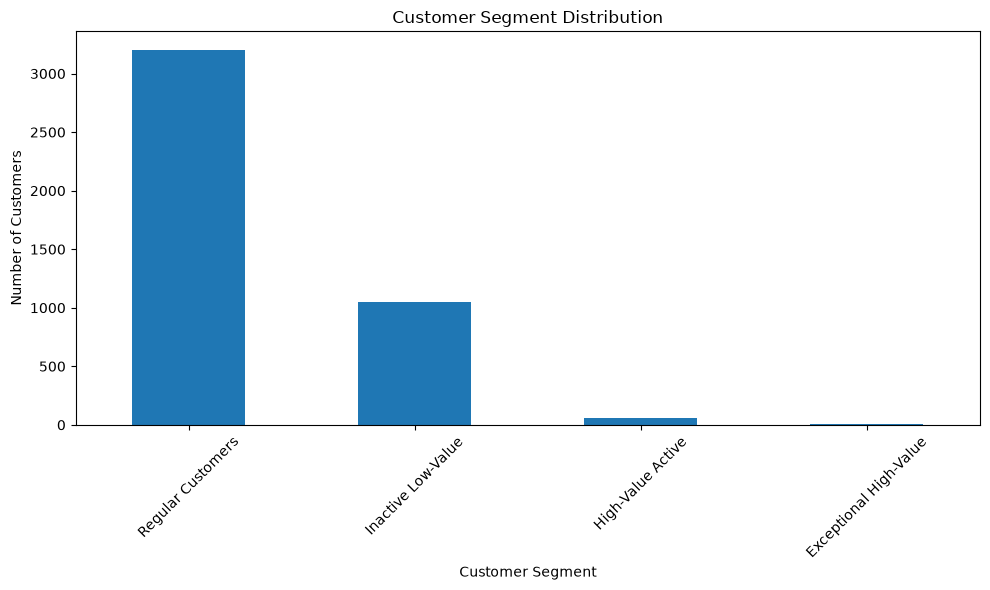

In [34]:
segment_counts = rfm["Segment"].value_counts()

plt.figure(figsize=(10, 6))
segment_counts.plot(kind="bar")

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

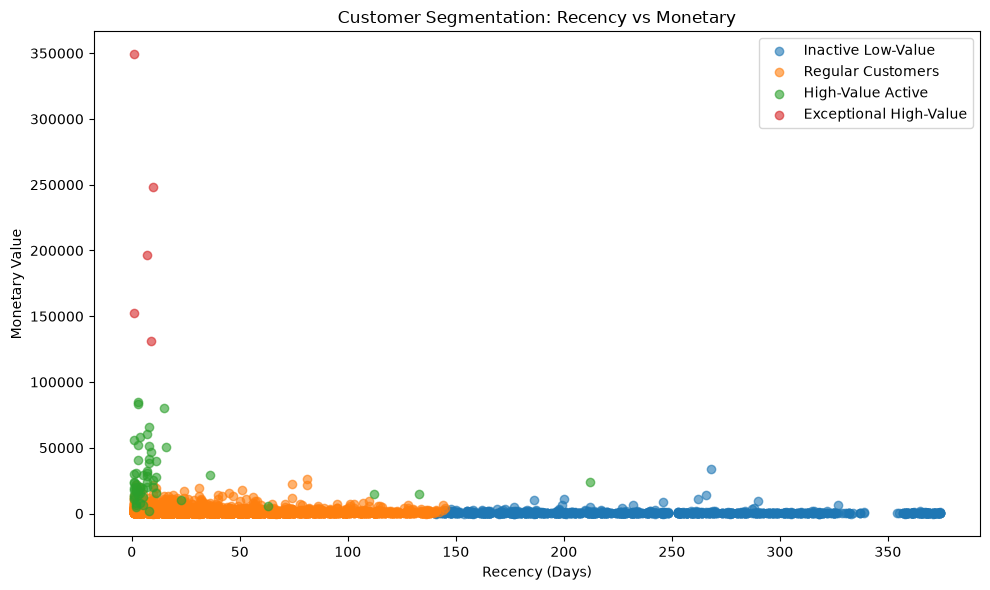

In [35]:
plt.figure(figsize=(10, 6))

for segment in rfm["Segment"].unique():
    segment_data = rfm[rfm["Segment"] == segment]
    
    plt.scatter(
        segment_data["Recency"],
        segment_data["Monetary"],
        label=segment,
        alpha=0.6
    )

plt.title("Customer Segmentation: Recency vs Monetary")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary Value")
plt.legend()
plt.tight_layout()
plt.show()

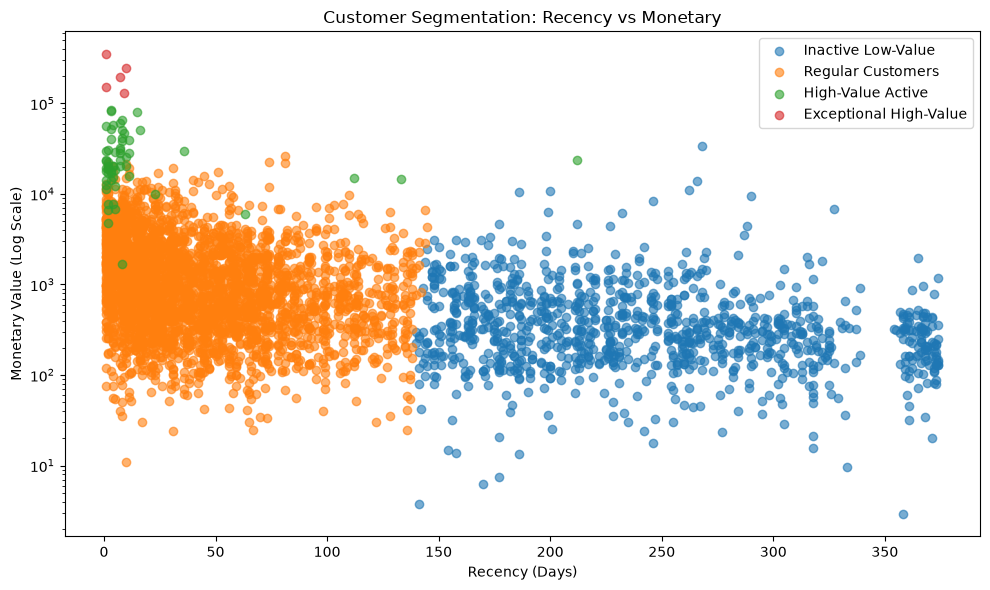

In [36]:
plt.figure(figsize=(10, 6))

for segment in rfm["Segment"].unique():
    segment_data = rfm[rfm["Segment"] == segment]
    
    plt.scatter(
        segment_data["Recency"],
        segment_data["Monetary"],
        label=segment,
        alpha=0.6
    )

plt.yscale("log")

plt.title("Customer Segmentation: Recency vs Monetary")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary Value (Log Scale)")
plt.legend()
plt.tight_layout()
plt.show()

In [37]:
rfm.to_csv(
    "../data/customer_segments.csv",
    index=False
)

print("Customer segmentation saved successfully.")
print(f"Rows: {len(rfm)}")
print(f"Columns: {len(rfm.columns)}")

Customer segmentation saved successfully.
Rows: 4312
Columns: 10


In [38]:
rfm.shape

(4312, 10)

In [39]:
import joblib

joblib.dump(final_kmeans, "../data/customer_kmeans_model.pkl")
joblib.dump(scaler, "../data/customer_rfm_scaler.pkl")

print("K-Means model saved successfully.")
print("RFM scaler saved successfully.")

K-Means model saved successfully.
RFM scaler saved successfully.


In [40]:
import joblib

loaded_kmeans = joblib.load("../data/customer_kmeans_model.pkl")
loaded_scaler = joblib.load("../data/customer_rfm_scaler.pkl")

print("K-Means model loaded successfully.")
print("Scaler loaded successfully.")

K-Means model loaded successfully.
Scaler loaded successfully.


In [41]:
print("Customer Analysis Complete")
print(f"Customers analyzed: {rfm['Customer ID'].nunique()}")
print(f"Segments created: {rfm['Segment'].nunique()}")
print("\nSegment distribution:")
print(rfm["Segment"].value_counts())

Customer Analysis Complete
Customers analyzed: 4312
Segments created: 4

Segment distribution:
Segment
Regular Customers         3201
Inactive Low-Value        1047
High-Value Active           59
Exceptional High-Value       5
Name: count, dtype: int64
